## Analiza în componente principale (ACP)

**Importuri pentru PCA**  
- `StandardScaler` – standardizează variabilele;  
- `PCA` – calculează componentele principale;  
- `matplotlib.pyplot` – grafice.

In [79]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

**Pregătirea datelor**  
- `variabile` = coloanele numerice (fără `Code` și `Country`);  
- `X` = matricea observații × variabile (39 × 12);  
- `X_std` = datele standardizate: din fiecare coloană se scade media și se împarte la abaterea standard. Astfel toate variabilele au aceeași importanță în PCA, indiferent de scală.

In [99]:
dna_df = pd.read_csv('./data_in/ADN/Y_DNA_Tari.csv', index_col="Code")
variabile = dna_df.columns[1:]
X = dna_df[variabile].values

# standardizare (media 0, abatere standard 1)
X_std = StandardScaler().fit_transform(X)
dna_df.head()

,Country,I1,I2a,I2b,R1a,R1b,G,J2,J1,E1b1b,T,Q,N
Code,,,,,,,,,,,,,
ALB,Albania,2.0,12.0,1.5,9.0,16.0,1.5,19.5,2.0,27.5,1.0,0.0,0.0
AUT,Austria,12.0,7.0,2.5,19.0,32.0,7.5,9.0,1.0,8.0,1.0,0.5,0.5
BLR,Belarus,5.5,17.5,1.0,51.0,5.5,1.5,2.5,1.0,4.0,0.0,0.0,10.0
BEL,Belgium,12.0,3.0,4.5,4.0,61.0,4.0,4.0,1.0,5.0,1.0,0.5,0.0
BIH,Bosnia-Herzegovina,3.0,55.5,0.0,15.0,3.5,1.5,4.0,0.5,12.0,1.0,2.0,2.0


**Aplicarea PCA**  
- `pca.fit_transform(X_std)` calculează componentele principale și întoarce `C`, **scorurile** fiecărei țări pe fiecare componentă;  
- `alpha` = **valorile proprii** – varianța explicată de fiecare componentă (pe date standardizate, suma lor ≈ numărul de variabile);  
- tabelul arată, pentru fiecare componentă, valoarea proprie, procentul de varianță explicată și procentul cumulat.

In [81]:
pca = PCA()
C = pca.fit_transform(X_std)  # scorurile (componentele principale)

alpha = pca.explained_variance_  # valorile proprii
pd.DataFrame({
    'Valoare proprie': alpha,
    'Varianta explicata (%)': pca.explained_variance_ratio_ * 100,
    'Varianta cumulata (%)': np.cumsum(pca.explained_variance_ratio_) * 100,
}, index=[f'C{i+1}' for i in range(len(alpha))])


,Valoare proprie,Varianta explicata (%),Varianta cumulata (%)
C1,4.467878,36.277641,36.277641
C2,2.943963,23.903975,60.181616
C3,1.626036,13.202858,73.384473
C4,0.950057,7.714142,81.098615
C5,0.684260,5.555960,86.654575
C6,0.519142,4.215256,90.869832
C7,0.378419,3.072635,93.942466
C8,0.287782,2.336693,96.279159
C9,0.220482,1.790242,98.069401
C10,0.152804,1.240717,99.310119


### Plot varianta (scree plot)
Graficul valorilor proprii, în ordine descrescătoare. Ne ajută să decidem câte componente păstrăm:  
- **Criteriul Kaiser**: păstrăm componentele cu valoarea proprie > 1 (linia roșie), adică acelea care explică mai mult decât o singură variabilă originală;  
- **Criteriul cotului**: păstrăm componentele dinaintea punctului în care curba se aplatizează.

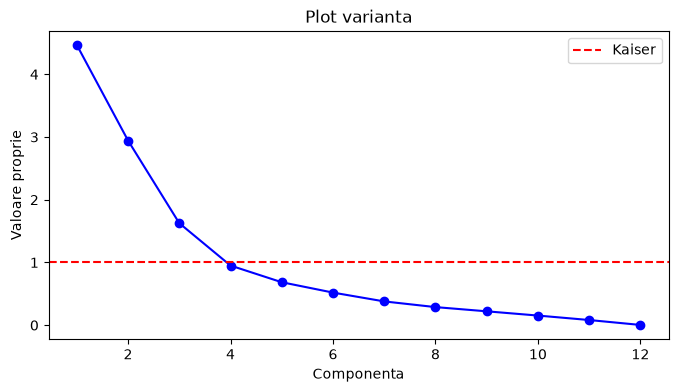

Numar componente semnificative (Kaiser): 3


In [82]:
plt.figure(figsize=(8, 4))
plt.plot(range(1, len(alpha) + 1), alpha, 'bo-')
plt.axhline(1, color='r', linestyle='--', label='Kaiser')
plt.xlabel('Componenta')
plt.ylabel('Valoare proprie')
plt.title('Plot varianta')
plt.legend()
plt.show()

nr_comp = int(np.sum(alpha > 1))
print('Numar componente semnificative (Kaiser):', nr_comp)

### Corelatii factoriale (loadings)
Corelația dintre fiecare variabilă originală și fiecare componentă: $r_{x,c} = a \cdot \sqrt{\alpha}$, unde $a$ sunt vectorii proprii (`pca.components_`) și $\alpha$ valorile proprii.  
Valorile sunt între -1 și 1: o valoare apropiată de ±1 înseamnă că acea haplogrupă „definește” componenta respectivă. Așa interpretăm ce reprezintă fiecare componentă.

In [83]:
# corelatia dintre variabilele observate si componente
r_xc = pca.components_.T * np.sqrt(alpha)
r_xc_df = pd.DataFrame(r_xc, index=variabile, columns=[f'C{i+1}' for i in range(len(alpha))])
r_xc_df.round(3)

,C1,C2,C3,C4,C5,C6,C7,C8,C9,C10,C11,C12
I1,-0.690,0.343,0.076,0.490,0.048,-0.304,-0.240,-0.003,0.169,-0.026,-0.069,0.015
I2a,0.274,-0.652,0.606,-0.179,-0.145,0.100,-0.071,0.189,0.216,0.081,0.042,0.019
I2b,-0.315,0.850,0.253,-0.075,0.108,-0.177,0.081,0.077,-0.088,0.247,0.103,0.004
R1a,-0.419,-0.645,-0.153,-0.288,0.553,-0.090,0.006,-0.090,-0.072,0.017,-0.020,0.025
R1b,-0.059,0.908,-0.017,-0.235,-0.138,0.327,-0.051,-0.066,-0.032,-0.081,-0.034,0.033
G,0.731,0.439,0.055,0.065,0.291,-0.080,0.372,0.176,0.138,-0.086,-0.070,0.004
J2,0.939,0.011,-0.061,0.195,0.030,-0.165,-0.039,-0.133,0.000,-0.121,0.198,0.014
J1,0.858,0.044,-0.186,0.087,0.129,0.006,-0.304,0.311,-0.197,0.011,-0.041,0.003
E1b1b,0.781,-0.198,0.378,0.011,-0.274,-0.274,0.090,-0.179,-0.153,0.069,-0.124,0.013
T,0.780,0.026,-0.391,0.268,0.150,0.258,-0.050,-0.179,0.145,0.216,-0.032,0.001


**Cercul corelațiilor**  
Fiecare variabilă este un punct cu coordonatele (corelația cu C1, corelația cu C2).  
- puncte aproape de cerc → variabila este bine reprezentată de primele două componente;  
- puncte aproape de centru → variabila este slab reprezentată;  
- variabile apropiate între ele → corelate pozitiv; în părți opuse → corelate negativ.

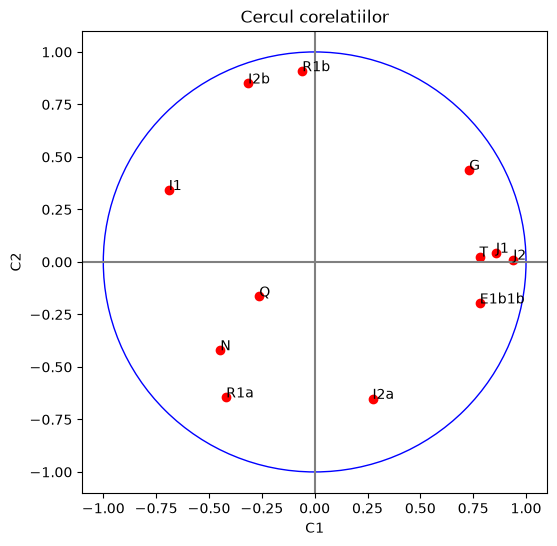

In [84]:
# cercul corelatiilor pentru C1 si C2
fig, ax = plt.subplots(figsize=(6, 6))
ax.add_patch(plt.Circle((0, 0), 1, fill=False, color='b'))
ax.axhline(0, color='gray'); ax.axvline(0, color='gray')
ax.scatter(r_xc_df['C1'], r_xc_df['C2'], color='r')
for v in variabile:
    ax.annotate(v, (r_xc_df.loc[v, 'C1'], r_xc_df.loc[v, 'C2']))
ax.set_xlim(-1.1, 1.1); ax.set_ylim(-1.1, 1.1)
ax.set_xlabel('C1'); ax.set_ylabel('C2')
ax.set_title('Cercul corelatiilor')
plt.show()

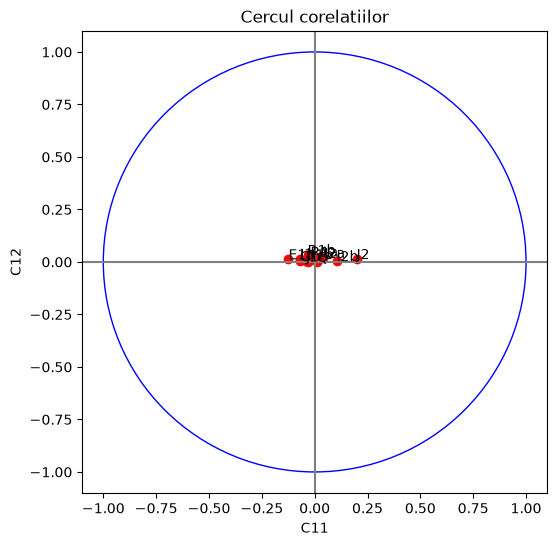

In [85]:
# cercul corelatiilor pentru C11 si C12
fig, ax = plt.subplots(figsize=(6, 6))
ax.add_patch(plt.Circle((0, 0), 1, fill=False, color='b'))
ax.axhline(0, color='gray'); ax.axvline(0, color='gray')
ax.scatter(r_xc_df['C11'], r_xc_df['C12'], color='r')
for v in variabile:
    ax.annotate(v, (r_xc_df.loc[v, 'C11'], r_xc_df.loc[v, 'C12']))
ax.set_xlim(-1.1, 1.1); ax.set_ylim(-1.1, 1.1)
ax.set_xlabel('C11'); ax.set_ylabel('C12')
ax.set_title('Cercul corelatiilor')
plt.show()

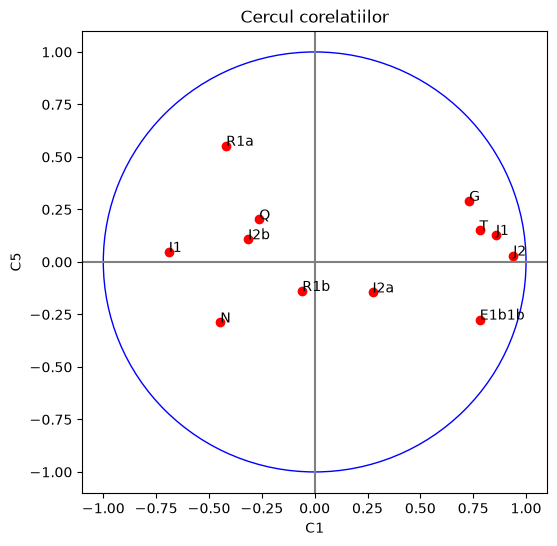

In [86]:
# cercul corelatiilor pentru C1 si C2
fig, ax = plt.subplots(figsize=(6, 6))
ax.add_patch(plt.Circle((0, 0), 1, fill=False, color='b'))
ax.axhline(0, color='gray'); ax.axvline(0, color='gray')
ax.scatter(r_xc_df['C1'], r_xc_df['C5'], color='r')
for v in variabile:
    ax.annotate(v, (r_xc_df.loc[v, 'C1'], r_xc_df.loc[v, 'C5']))
ax.set_xlim(-1.1, 1.1); ax.set_ylim(-1.1, 1.1)
ax.set_xlabel('C1'); ax.set_ylabel('C5')
ax.set_title('Cercul corelatiilor')
plt.show()

### Scorurile tarilor
Tabelul scorurilor (`C`) cu numele țărilor ca index. Un scor mare (pozitiv sau negativ) pe o componentă înseamnă că țara are valori mari pentru haplogrupele puternic corelate cu acea componentă.

In [87]:
scoruri_df = pd.DataFrame(C, index=dna_df['Country'], columns=[f'C{i+1}' for i in range(len(alpha))])
scoruri_df.round(3)

,C1,C2,C3,C4,C5,C6,C7,C8,C9,C10,C11,C12
Country,,,,,,,,,,,,
Albania,2.254,-0.668,0.239,-0.513,-1.543,-1.359,-0.361,-1.116,-0.862,-0.135,0.267,-0.087
Austria,0.538,0.911,0.020,-0.067,0.671,-0.372,0.813,0.219,0.589,-0.694,-0.303,0.044
Belarus,-1.100,-2.030,-0.715,-1.558,0.692,-0.523,-0.203,0.340,0.051,-0.214,0.031,0.036
Belgium,-0.416,2.344,0.044,-0.377,-0.364,0.515,0.010,0.083,0.020,0.013,-0.021,0.032
Bosnia-Herzegovina,0.311,-2.989,2.971,0.255,-0.737,1.546,-0.164,0.608,0.930,0.273,0.240,0.008
Bulgaria,2.187,-0.721,0.713,-0.175,-0.280,-0.809,0.160,0.173,-0.402,0.359,-0.580,0.042
Croatia,0.173,-1.878,1.519,-0.513,-0.176,0.317,-0.201,0.518,0.613,-0.069,0.209,-0.027
Czech Republic,-0.737,0.224,0.959,0.290,1.478,0.129,0.861,-0.257,-0.110,0.150,0.246,0.044
Cyprus,6.246,-0.026,-1.606,1.407,0.565,-0.570,-0.222,-0.239,0.329,-0.391,0.681,0.028


**Harta țărilor în planul C1–C2**  
Fiecare țară este plasată după scorurile pe primele două componente. Țările apropiate au structuri genetice asemănătoare; comparând cu cercul corelațiilor putem vedea ce haplogrupe le diferențiază (ex. țări cu R1a mare vs. țări cu R1b mare).

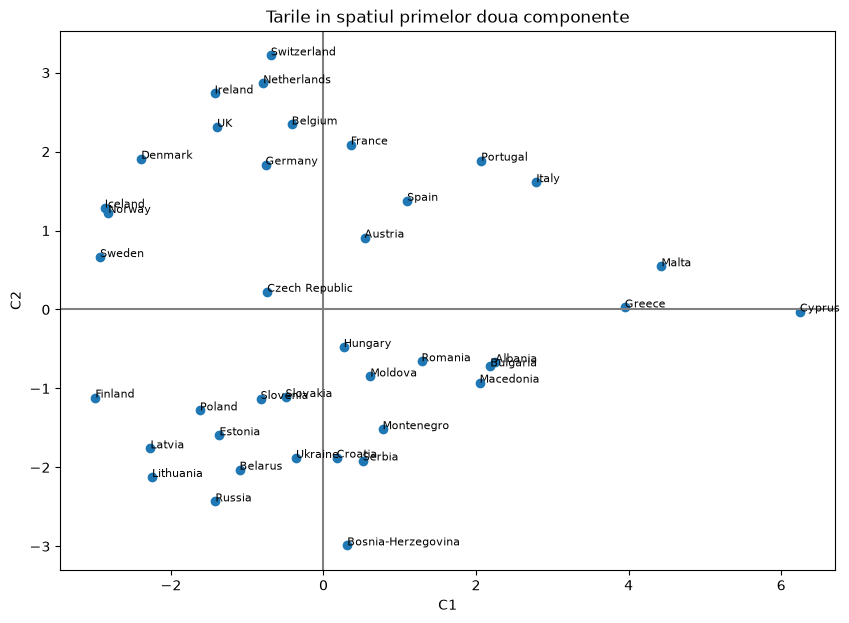

In [88]:
plt.figure(figsize=(10, 7))
plt.scatter(scoruri_df['C1'], scoruri_df['C2'])
for tara in scoruri_df.index:
    plt.annotate(tara, (scoruri_df.loc[tara, 'C1'], scoruri_df.loc[tara, 'C2']), fontsize=8)
plt.axhline(0, color='gray'); plt.axvline(0, color='gray')
plt.xlabel('C1'); plt.ylabel('C2')
plt.title('Tarile in spatiul primelor doua componente')
plt.show()

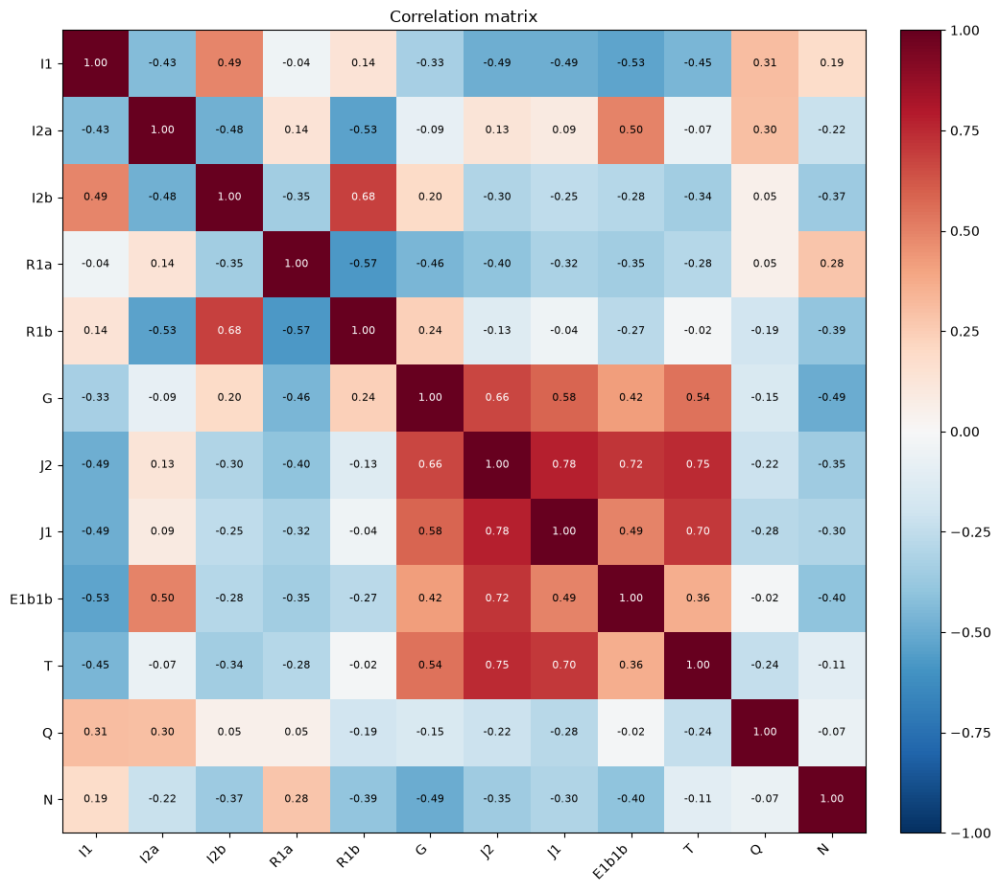

<Axes: title={'center': 'Correlation matrix'}>

In [89]:
dna_df = pd.read_csv('./data_in/ADN/Y_DNA_Tari.csv', index_col="Code")
variabile = dna_df.columns[1:]
X = dna_df[variabile].values

# standardizare (media 0, abatere standard 1)
X_std = StandardScaler().fit_transform(X)
X_std_df = pd.DataFrame(X_std, dna_df[variabile].index, dna_df[variabile].columns)

corr_df = pd.DataFrame(np.corrcoef(X_std_df.values, rowvar=False), X_std_df.columns, X_std_df.columns)

import utils as utils
utils.plot_corr_heatmap(corr_df)


<Axes: >

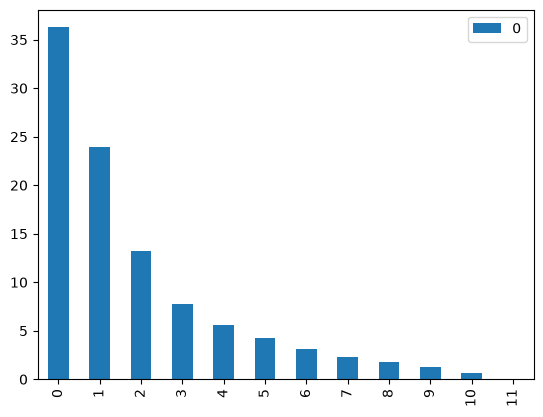

In [90]:
n,m = X_std.shape
ddof = 0 
correlation = (X_std.T @ X_std)/(n-ddof)

# utils.plot_corr_heatmap(pd.DataFrame(correlation))

eigenvalues, eigenvectors =  np.linalg.eigh(correlation)

eigenvalues.round(3)
order = np.argsort(eigenvalues)[::-1]

eigenvalues= eigenvalues[order]
eigenvectors = eigenvectors[:, order]

eigenvalues.round(5)

procente = eigenvalues*100/eigenvalues.sum()
pd.DataFrame(procente).plot(kind="bar", ylim=0)

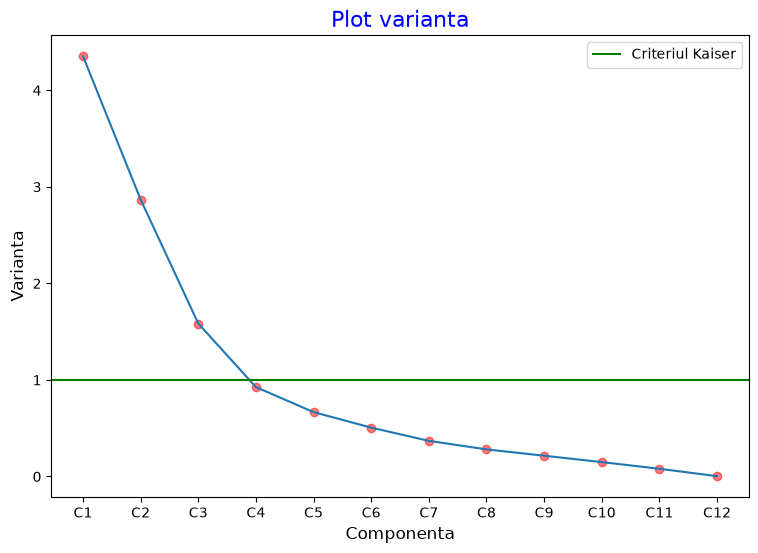

In [100]:
def explain_variance(eigenvalues: np.ndarray):
    procente = eigenvalues*100/sum(eigenvalues)
    t = pd.DataFrame(
        {
            "Varianta": eigenvalues,
            "Varianta cumulata": np.cumsum(eigenvalues),
            "Procent varianta": procente,
            "Procent cumulat": np.cumsum(procente)
        }, index=["c"+str(i+1) for i in range(len(eigenvalues))]
    )
    t.index.name = "Componenta"
    return t

explain_variance(eigenvalues)

utils.plot_variance(eigenvalues)

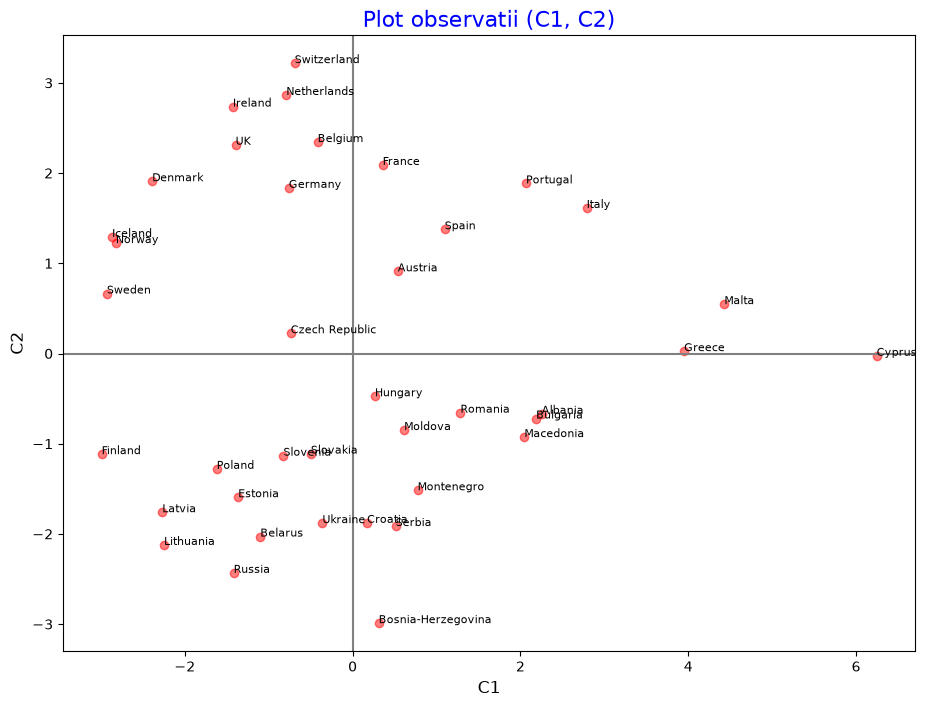

In [92]:
def principal_components(Z: pd.DataFrame, eigenvectors: np.ndarray):
    C = Z.values @ eigenvectors
    return pd.DataFrame(C, index=Z.index, columns=["C"+str(i+1) for i in range(C.shape[1])])

components = principal_components(X_std_df, eigenvectors)
components

utils.plot_observations(components, dna_df["Country"], "C1", "C2")

### Exemplu 2d

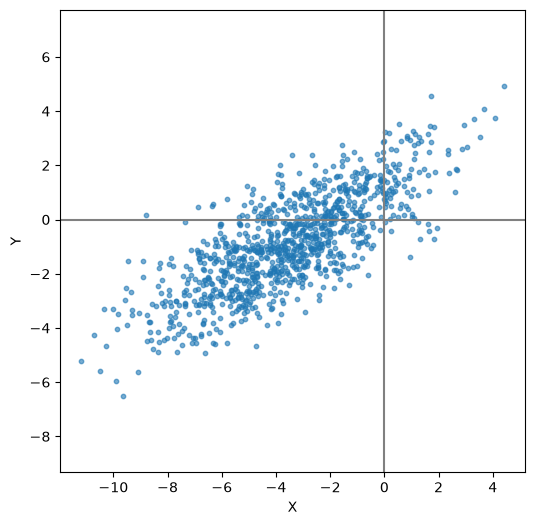

In [93]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# generam un set de date 2D in forma de elipsa inclinata
np.random.seed(420)
n_puncte = 1000
unghi = np.deg2rad(30)   # unghiul de inclinare
a, b = 3, 1              # semiaxa mare / semiaxa mica
centru = np.random.uniform(-10, 10, size=2)  # centrul elipsei (aleator)

# puncte dintr-o distributie normala, alungite pe axa x
puncte = np.random.randn(n_puncte, 2) * [a, b]

# rotim punctele cu unghiul ales, apoi le mutam in centru
R = np.array([[np.cos(unghi), -np.sin(unghi)],
              [np.sin(unghi),  np.cos(unghi)]])
elipsa = puncte @ R.T + centru
elipsa_df = pd.DataFrame(elipsa, columns=['X', 'Y'])

plt.figure(figsize=(6, 6))
plt.scatter(elipsa_df['X'], elipsa_df['Y'], s=10, alpha=0.6)
plt.xlabel('X'); 
plt.axis('equal')
plt.ylabel('Y')
plt.axhline(0, color='gray', linestyle='-'); plt.axvline(0, color='gray', linestyle='-')



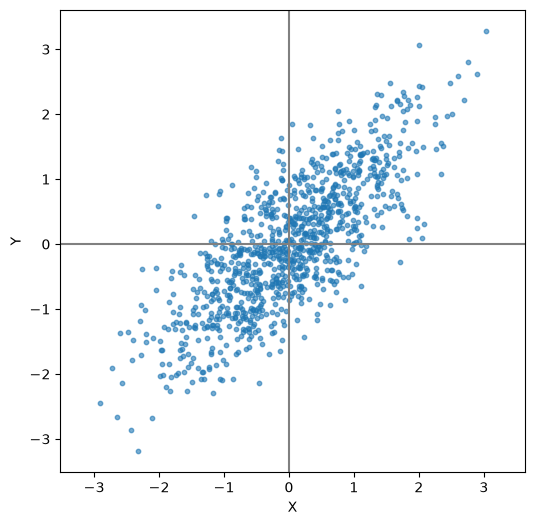

In [94]:
elipsa = StandardScaler().fit_transform(elipsa)

elipsa_df = pd.DataFrame(elipsa, columns=['X', 'Y'])

plt.figure(figsize=(6, 6))
plt.scatter(elipsa_df['X'], elipsa_df['Y'], s=10, alpha=0.6)
plt.xlabel('X'); 
plt.axis('equal')
plt.ylabel('Y')
plt.axhline(0, color='gray', linestyle='-'); plt.axvline(0, color='gray', linestyle='-')


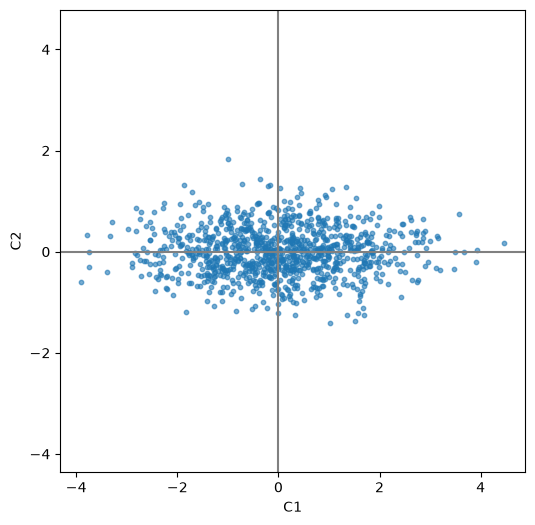

In [95]:
pca = PCA()
pca.fit(elipsa)
pca.explained_variance_

mappedData = elipsa @ pca.components_.T
mappedData_df = pd.DataFrame(mappedData, columns=["C1", "C2"])

plt.figure(figsize=(6, 6))
plt.scatter(mappedData_df['C1'], mappedData_df['C2'], s=10, alpha=0.6)
plt.xlabel('C1'); 
plt.axis('equal')
plt.ylabel('C2')
plt.axhline(0, color='gray', linestyle='-'); plt.axvline(0, color='gray', linestyle='-')

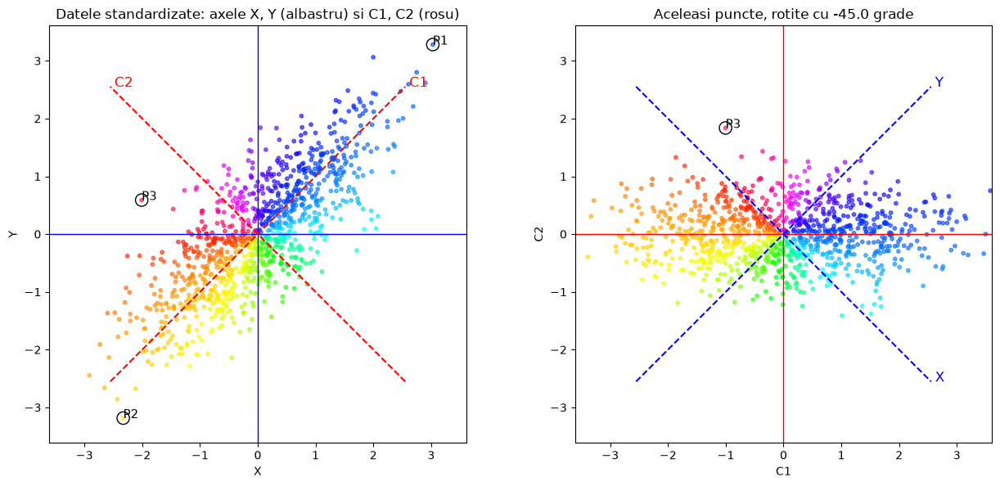

Matricea de rotatie V =
 [[ 0.7071  0.7071]
 [-0.7071  0.7071]]
V @ V.T =
 [[ 1. -0.]
 [-0.  1.]]
det(V) = 1.0
Distante pastrate: True


In [96]:
pca = PCA()
scoruri = pca.fit_transform(elipsa)   # datele sunt deja standardizate (medie 0)
V = pca.components_                   # randurile = directiile C1, C2

unghi_rot = np.degrees(np.arctan2(V[0, 1], V[0, 0]))
idx = [np.argmax(scoruri[:, 0]), np.argmin(scoruri[:, 0]), np.argmax(scoruri[:, 1])]
culori = np.arctan2(elipsa[:, 1], elipsa[:, 0])
L = np.abs(elipsa).max() * 1.1        # lungimea axelor desenate

fig, axs = plt.subplots(1, 2, figsize=(13, 6))

# stanga: datele standardizate, axele X, Y + noile axe C1, C2
ax = axs[0]
ax.scatter(elipsa[:, 0], elipsa[:, 1], c=culori, cmap='hsv', s=10, alpha=0.6)
ax.axhline(0, color='b', lw=1); ax.axvline(0, color='b', lw=1)
for i, v in enumerate(V):
    ax.plot([-L * v[0], L * v[0]], [-L * v[1], L * v[1]], 'r--', lw=1.5)
    ax.text(*(L * v), f' C{i+1}', color='r', fontsize=12)
ax.set_xlabel('X'); ax.set_ylabel('Y')
ax.set_title('Datele standardizate: axele X, Y (albastru) si C1, C2 (rosu)')

# dreapta: aceleasi puncte, rotite astfel incat C1, C2 devin orizontala / verticala
ax = axs[1]
ax.scatter(scoruri[:, 0], scoruri[:, 1], c=culori, cmap='hsv', s=10, alpha=0.6)
ax.axhline(0, color='r', lw=1); ax.axvline(0, color='r', lw=1)
for i, nume in enumerate(['X', 'Y']):
    v = V[:, i]                       # vechea axa, exprimata in coordonatele (C1, C2)
    ax.plot([-L * v[0], L * v[0]], [-L * v[1], L * v[1]], 'b--', lw=1.5)
    ax.text(*(L * v), f' {nume}', color='b', fontsize=12)
ax.set_xlabel('C1'); ax.set_ylabel('C2')
ax.set_title(f'Aceleasi puncte, rotite cu {-unghi_rot:.1f} grade')

# acelasi set de puncte marcate in ambele grafice
for ax, P in zip(axs, [elipsa, scoruri]):
    for k, j in enumerate(idx):
        ax.scatter(*P[j], s=120, facecolors='none', edgecolors='k')
        ax.annotate(f'P{k+1}', P[j], fontsize=11)
    ax.set_xlim(-L, L); ax.set_ylim(-L, L)
    ax.set_aspect('equal')

plt.tight_layout()
plt.show()

print('Matricea de rotatie V =\n', V.round(4))
print('V @ V.T =\n', (V @ V.T).round(6))
print('det(V) =', round(np.linalg.det(V), 6))
print('Distante pastrate:', np.allclose(np.linalg.norm(elipsa, axis=1), np.linalg.norm(scoruri, axis=1)))


In [97]:
# generam un set de date 3D in forma de elipsoid inclinat
np.random.seed(42)
n_puncte = 1000
a, b, c = 4, 2, 0.5                            # semiaxele elipsoidului
centru3 = np.random.uniform(-10, 10, size=3)   # centrul (aleator)

puncte3 = np.random.randn(n_puncte, 3) * [a, b, c]

# matrice de rotatie aleatoare (ortogonala, det = +1)
R3, _ = np.linalg.qr(np.random.randn(3, 3))
if np.linalg.det(R3) < 0:
    R3[:, 0] *= -1

elipsoid = puncte3 @ R3.T + centru3
elipsoid = StandardScaler().fit_transform(elipsoid)
elipsoid_df = pd.DataFrame(elipsoid, columns=['X', 'Y', 'Z'])


In [98]:
from scipy.linalg import expm, logm
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

pca3 = PCA()
scoruri3 = pca3.fit_transform(elipsoid)
V3 = pca3.components_.copy()
if np.linalg.det(V3) < 0:                 # rotatie pura (fara oglindire)
    V3[2] *= -1; scoruri3[:, 2] *= -1

# expm(t * A) trece lin de la I (t=0, nicio rotatie) la V3 (t=1, rotatia PCA)
A = logm(V3).real
culori3 = scoruri3[:, 0]
L3 = np.abs(elipsoid).max() * 1.1

fig = plt.figure(figsize=(7, 7))
ax = fig.add_subplot(projection='3d')

def deseneaza(t):
    ax.clear()
    R = expm(t * A)
    P = elipsoid @ R.T                    # punctele rotite partial
    ax.scatter(P[:, 0], P[:, 1], P[:, 2], c=culori3, cmap='viridis', s=8, alpha=0.6)

    # directiile C1, C2, C3 se rotesc odata cu punctele
    for i, v in enumerate(V3 @ R.T):
        capat = v * 2 * np.sqrt(pca3.explained_variance_[i])
        ax.quiver(0, 0, 0, *capat, color='r', linewidth=2)
        ax.text(*capat, f' C{i+1}', color='r', fontsize=12)

    ax.set_xlim(-L3, L3); ax.set_ylim(-L3, L3); ax.set_zlim(-L3, L3)
    ax.set_box_aspect((1, 1, 1))
    ax.view_init(elev=20, azim=35)
    if t < 1:
        ax.set_xlabel('X'); ax.set_ylabel('Y'); ax.set_zlabel('Z')
    else:
        ax.set_xlabel('C1'); ax.set_ylabel('C2'); ax.set_zlabel('C3')
    ax.set_title(f'Rotatie: {t * 100:.0f}%')

cadre = np.concatenate([np.zeros(10), np.linspace(0, 1, 40), np.ones(15)])
anim = FuncAnimation(fig, deseneaza, frames=cadre, interval=80)
plt.close(fig)

# verificare: la final punctele = scorurile PCA
print('Final = scoruri PCA:', np.allclose(elipsoid @ V3.T, scoruri3))
HTML(anim.to_jshtml())

Final = scoruri PCA: True
